# 文化产业 · 逐表数据可视化分析

基于国家统计局「数据库 — 季度数据」（规模以上文化及相关产业，2025Q2 — 2026Q2 共 5 期）
对**文化产业**主题的 6 张数据表逐一进行可视化分析。

| # | 数据表 | 分析内容 |
| --- | --- | --- |
| 1 | 规模以上文化及相关产业企业利润总额 | 利润累计柱 + 累计增长线（双轴） |
| 2 | 规模以上文化及相关产业企业资产总计 | 资产季末走势 + 同比增长 |
| 3 | 按行业分营业收入 | 三大行业分组柱状图 + 核心/相关领域环形图 |
| 4 | 按行业分营业收入比重 | 三大行业占比 100% 堆积横条 |
| 5 | 按产业和领域分营业收入 | 九大类堆积柱 + 最新期排行横向条形 |
| 6 | 按产业和领域分营业收入比重 | 九大类占比棒棒糖图 |


**口径说明**：营业收入与利润为**累计值**口径，资产总计为**季末存量**口径；
"累计增长 / 同比"均由统计局发布，非本 Notebook 计算；九大类划分依据《文化及相关产业分类（2018）》。

In [1]:
# 0 环境与工具函数
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = ['Times New Roman', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.22
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.titlesize'] = 12.5
plt.rcParams['axes.titleweight'] = 'bold'

QMAP = {'一': 1, '二': 2, '三': 3, '四': 4}
DATA_DIR = next(c for c in [Path('data'), Path('文化/data'), Path('.')]
                if (c / '规模以上文化及相关产业企业利润总额.csv').exists())
PAL = ['#0071e3', '#34c759', '#ff9f0a', '#ff375f', '#bf5af2', '#64d2ff', '#ffd60a', '#8e8e93', '#a2845e']

# 九大类（短名 → 指标前缀）
INDUSTRIES = [
    ('新闻信息服务', '规模以上新闻信息服务营业收入累计值'),
    ('内容创作生产', '规模以上内容创作生产营业收入累计值'),
    ('创意设计服务', '规模以上创意设计服务营业收入累计值'),
    ('文化传播渠道', '规模以上文化传播渠道营业收入累计值'),
    ('文化投资运营', '规模以上文化投资运营营业收入累计值'),
    ('文化娱乐休闲', '规模以上文化娱乐休闲服务营业收入累计值'),
    ('文化辅助中介', '规模以上文化辅助生产和中介服务营业收入累计值'),
    ('文化装备生产', '规模以上文化装备生产营业收入累计值'),
    ('文化消费终端', '规模以上文化消费终端生产营业收入累计值'),
]


def load_table(fname):
    """解析国家统计局季度 CSV，返回 (季度列表[时间正序], {指标名: 数值列表})。"""
    text = (DATA_DIR / fname).read_text(encoding='utf-8-sig')
    quarters, rows = None, {}
    for line in text.splitlines():
        if '\t' not in line:
            continue
        cells = [c.replace(',', '').strip() for c in line.split('\t')]
        first = re.sub(r'\s+', '', cells[0] or '')
        if first == '指标':
            quarters = []
            for c in cells[1:]:
                if not c:
                    continue
                m = re.match(r'(\d{4})年第([一二三四])季度', c)
                if m:
                    quarters.append(f'{m.group(1)}Q{QMAP[m.group(2)]}')
            continue
        if not first or first.startswith(('注', '数据库', '时间', '数据来源')):
            continue
        vals = []
        for c in cells[1:]:
            try:
                vals.append(float(c))
            except ValueError:
                vals.append(None)
        vals = (vals + [None] * len(quarters))[:len(quarters)]  # 按季度轴对齐
        rows[first] = vals
    quarters = list(reversed(quarters))
    rows = {k: list(reversed(v)) for k, v in rows.items()}
    return quarters, rows


def col(rows, prefix):
    key = next((k for k in rows if k.startswith(prefix)), None)
    if key is None:
        raise KeyError(f'未找到指标：{prefix}')
    return rows[key]


def short_q(q):
    return q


print('数据目录：', DATA_DIR.resolve())
print('工具函数加载完成，可逐格运行下方分析。')

数据目录： C:\Users\21409\Desktop\商业数据分析+数据可视化\数据可视化\国家统计局数据可视化分析\文化\data
工具函数加载完成，可逐格运行下方分析。


## 表 1 · 规模以上文化及相关产业企业利润总额（累计）

**图 1** 双轴组合图：利润总额累计值（柱）与累计增长（线，右轴）。

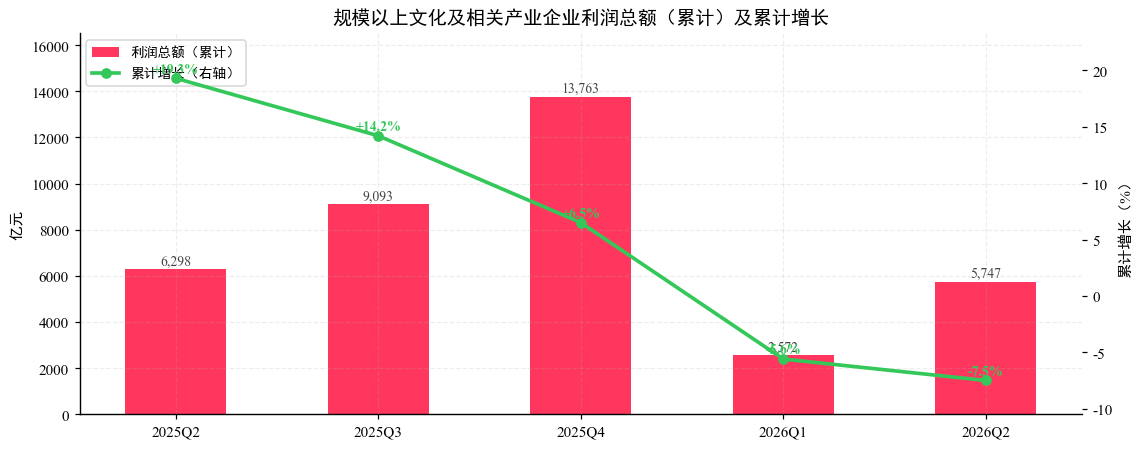

In [2]:
# 表 1：利润总额
quarters, rows = load_table('规模以上文化及相关产业企业利润总额.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

profit = col(rows, '规模以上文化及相关产业企业利润总额累计值')
growth = col(rows, '规模以上文化及相关产业企业利润总额累计增长')

fig, ax = plt.subplots(figsize=(10.5, 4.2))
bars = ax.bar(x, profit, 0.5, label='利润总额（累计）', color=PAL[3])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 200,
            f'{b.get_height():,.0f}', ha='center', fontsize=9, color='#444444')
ax2 = ax.twinx()
ax2.plot(x, growth, 'o-', color=PAL[1], lw=2.4, label='累计增长（右轴）')
for xi, yi in zip(x, growth):
    ax2.text(xi, yi + 0.5, f'{yi:+.1f}%', ha='center', fontsize=9,
             fontweight='bold', color=PAL[1])
ax2.set_ylabel('累计增长（%）')
ax2.set_ylim(min(growth) - 3, max(growth) + 4)
ax2.grid(False)
ax.set_xticks(x, labels)
ax.set_ylabel('亿元')
ax.set_ylim(0, max(profit) * 1.2)
ax.set_title('规模以上文化及相关产业企业利润总额（累计）及累计增长')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

## 表 2 · 规模以上文化及相关产业企业资产总计（季末）

**图 1** 面积折线图：资产总计季末走势 + 同比增长（右轴）。

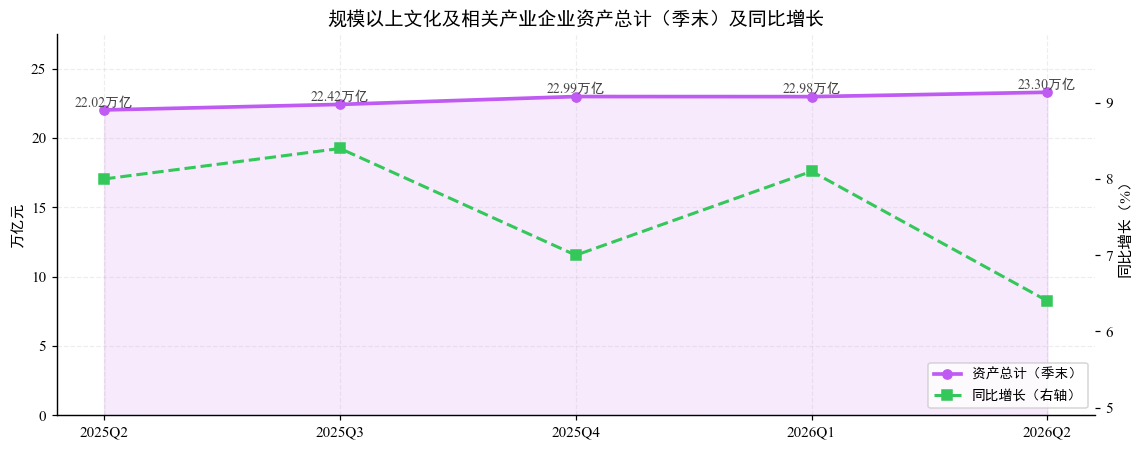

In [3]:
# 表 2：资产总计
quarters, rows = load_table('规模以上文化及相关产业企业资产总计.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

assets = col(rows, '规模以上文化及相关产业企业资产总计季末值')
yoy = col(rows, '规模以上文化及相关产业企业资产总计同比增长')

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.plot(x, [v / 10000 for v in assets], 'o-', color=PAL[4], lw=2.4, label='资产总计（季末）')
ax.fill_between(x, 0, [v / 10000 for v in assets], color=PAL[4], alpha=0.12)
for xi, yi in zip(x, assets):
    ax.text(xi, yi / 10000 + 0.25, f'{yi / 10000:.2f}万亿', ha='center', fontsize=9, color='#444444')
ax2 = ax.twinx()
ax2.plot(x, yoy, 's--', color=PAL[1], lw=2, label='同比增长（右轴）')
ax2.set_ylabel('同比增长（%）')
ax2.set_ylim(min(yoy) - 1.5, max(yoy) + 1.5)
ax2.grid(False)
ax.set_xticks(x, labels)
ax.set_ylabel('万亿元')
ax.set_ylim(0, max(assets) / 10000 * 1.18)
ax.set_title('规模以上文化及相关产业企业资产总计（季末）及同比增长')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

## 表 3 · 按行业分规模以上文化及相关产业企业营业收入（累计）

**图 1** 分组柱状图：文化制造 / 批发零售 / 文化服务业三大行业营业收入（累计值）；
**图 2** 环形图：核心领域 vs 相关领域（最新季度）。

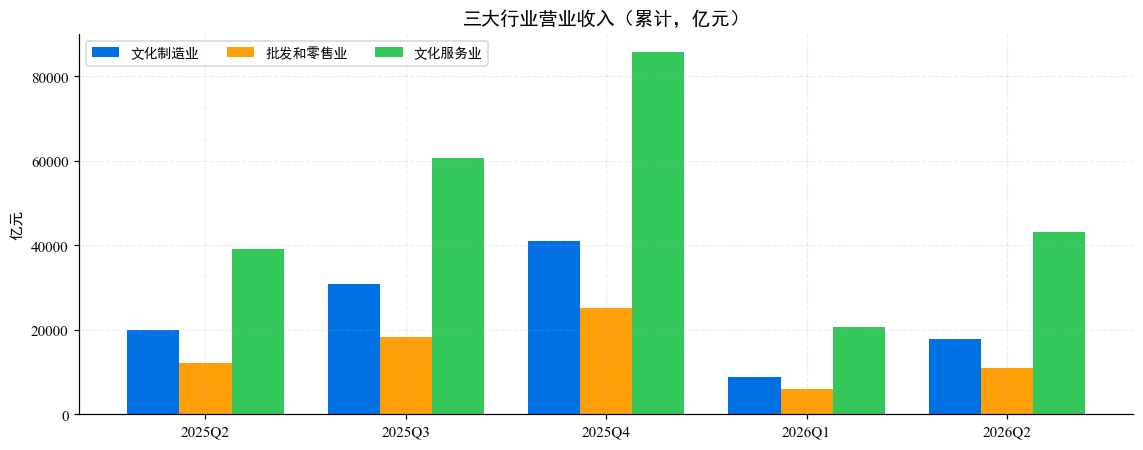

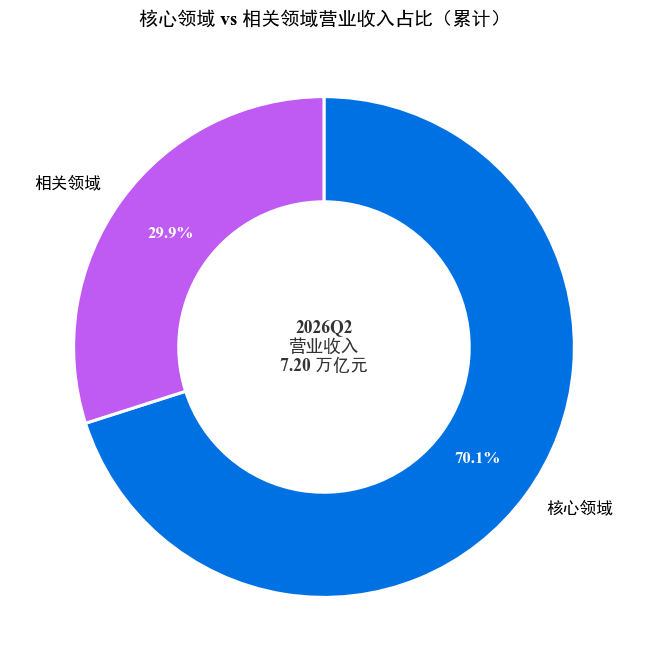

In [4]:
# 表 3：按行业分营业收入
quarters, rows = load_table('按行业分规模以上文化及相关产业企业营业收入.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

mfg = col(rows, '规模以上文化制造业企业营业收入累计值')
wholesale = col(rows, '规模以上文化批发和零售业企业营业收入累计值')
service = col(rows, '规模以上文化服务业企业营业收入累计值')
core = col(rows, '规模以上文化核心领域企业营业收入累计值')
related = col(rows, '规模以上文化相关领域企业营业收入累计值')
rev = [m + w + s for m, w, s in zip(mfg, wholesale, service)]  # 三大行业之和 ≈ 总营收

# 图 1：三大行业分组柱状图
w = 0.26
fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.bar(x - w, mfg, w, label='文化制造业', color=PAL[0])
ax.bar(x, wholesale, w, label='批发和零售业', color=PAL[2])
ax.bar(x + w, service, w, label='文化服务业', color=PAL[1])
ax.set_xticks(x, labels)
ax.set_ylabel('亿元')
ax.set_title('三大行业营业收入（累计，亿元）')
ax.legend(ncol=3, fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

# 图 2：核心 vs 相关领域环形图（最新季度）
latest = len(quarters) - 1
fig, ax = plt.subplots(figsize=(7.2, 6.2))
wedges, texts, autotexts = ax.pie(
    [core[latest], related[latest]], labels=['核心领域', '相关领域'],
    autopct='%1.1f%%', startangle=90, counterclock=False, colors=[PAL[0], PAL[4]],
    pctdistance=0.76, wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 11})
for t in autotexts:
    t.set_color('white'); t.set_fontweight('bold')
ax.text(0, 0, f'{quarters[latest]}\n营业收入\n{rev[latest] / 10000:.2f} 万亿元',
        ha='center', va='center', fontsize=11.5, fontweight='bold', color='#333333')
ax.set_title('核心领域 vs 相关领域营业收入占比（累计）')
plt.tight_layout()
plt.show()

## 表 4 · 三大行业营业收入比重（官方口径）

**图 1** 100% 堆积横向条形图：三大行业占营业收入比重（官方发布口径，5 期对比）。

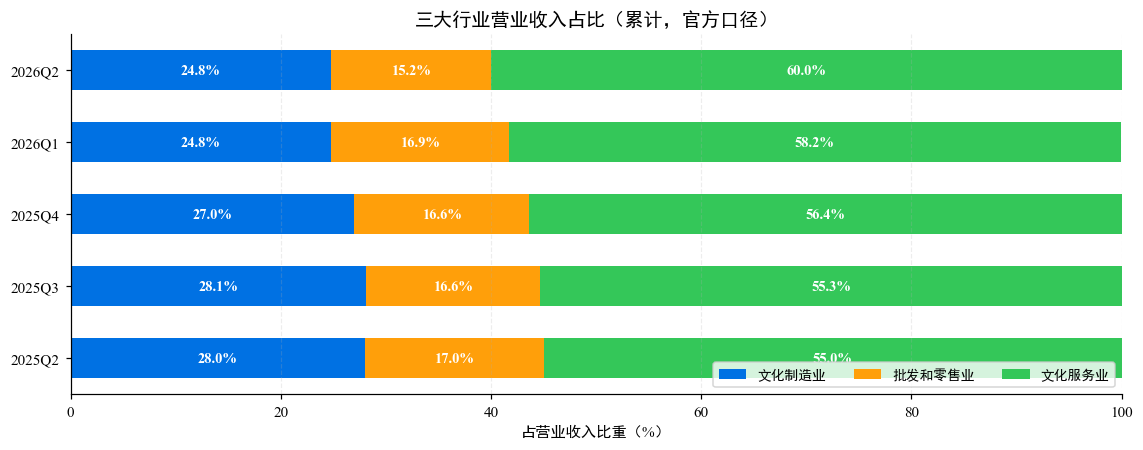

In [5]:
# 表 4：三大行业营业收入比重（比重文件名与内容互换，按内容读取）
quarters, rows = load_table('按产业和领域分规模以上文化及相关产业企业营业收入比重.csv')
y = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

mfg_s = col(rows, '规模以上文化制造业企业营业收入所占比重累计值')
wholesale_s = col(rows, '规模以上文化批发和零售业企业营业收入所占比重累计值')
service_s = col(rows, '规模以上文化服务业企业营业收入所占比重累计值')

fig, ax = plt.subplots(figsize=(10.5, 4.2))
left = np.zeros(len(quarters))
for c, vals in [('文化制造业', mfg_s), ('批发和零售业', wholesale_s), ('文化服务业', service_s)]:
    ax.barh(y, vals, 0.55, left=left, label=c, color=PAL[{'文化制造业': 0, '批发和零售业': 2, '文化服务业': 1}[c]])
    for yi, v in enumerate(vals):
        ax.text(left[yi] + v / 2, yi, f'{v:.1f}%', ha='center', va='center',
                fontsize=9.5, color='white', fontweight='bold')
    left += np.array(vals)
ax.set_yticks(y, labels)
ax.set_xlim(0, 100)
ax.set_xlabel('占营业收入比重（%）')
ax.set_title('三大行业营业收入占比（累计，官方口径）')
ax.legend(ncol=3, loc='lower right', fontsize=9)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

## 表 5 · 按产业和领域分规模以上文化及相关产业企业营业收入（累计）

**图 1** 堆积柱状图：九大类营业收入构成（累计）；
**图 2** 横向条形图：最新季度九大类排行（括号内为累计增长）。

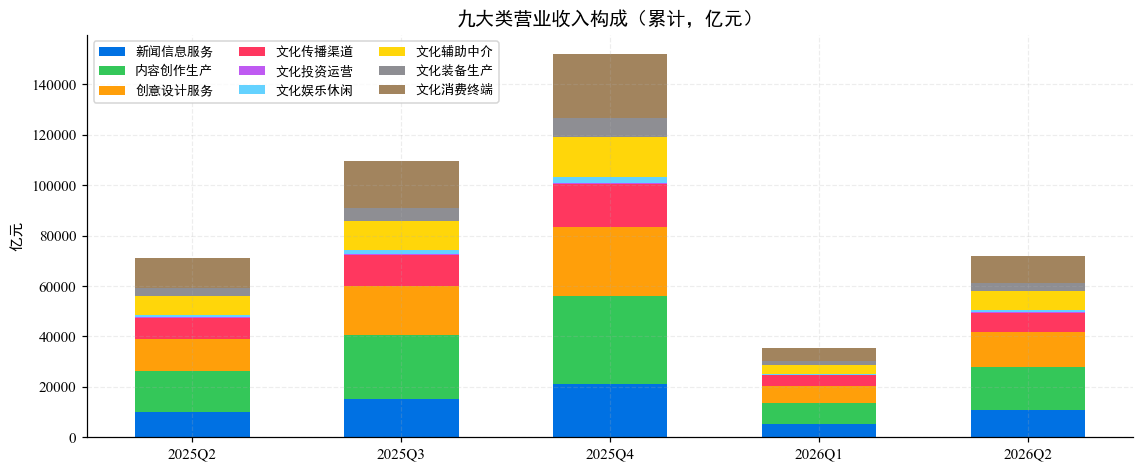

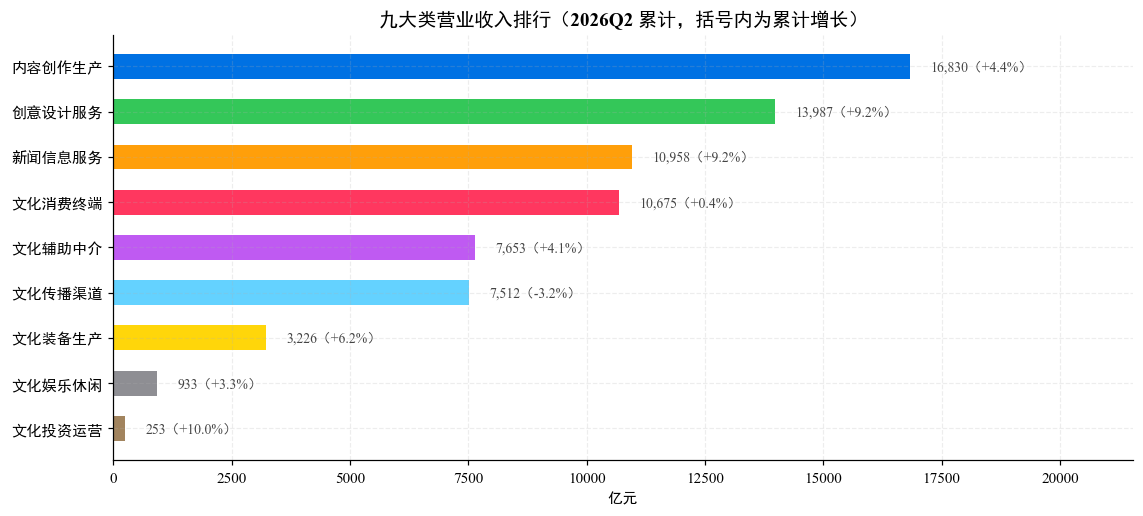

In [6]:
# 表 5：按产业和领域分营业收入
quarters, rows = load_table('按产业和领域分规模以上文化及相关产业企业营业收入.csv')
x = np.arange(len(quarters))
labels = [short_q(q) for q in quarters]

rev = col(rows, '规模以上文化及相关产业企业营业收入累计值')
ind_v = {name: col(rows, p) for name, p in INDUSTRIES}
ind_g = {name: col(rows, p.replace('营业收入累计值', '营业收入累计增长')) for name, p in INDUSTRIES}

# 图 1：九大类堆积柱状图
fig, ax = plt.subplots(figsize=(10.5, 4.4))
bottom = np.zeros(len(quarters))
for i, (name, _) in enumerate(INDUSTRIES):
    ax.bar(x, ind_v[name], 0.55, bottom=bottom, label=name, color=PAL[i % len(PAL)])
    bottom += np.array(ind_v[name])
ax.set_xticks(x, labels)
ax.set_ylabel('亿元')
ax.set_title('九大类营业收入构成（累计，亿元）')
ax.legend(ncol=3, fontsize=8.5, loc='upper left')
plt.tight_layout()
plt.show()

# 图 2：最新季度九大类排行横向条形图
latest = len(quarters) - 1
pairs = sorted([(n, ind_v[n][latest], ind_g[n][latest]) for n, _ in INDUSTRIES], key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(10.5, 4.8))
bars = ax.barh([p[0] for p in pairs], [p[1] for p in pairs], 0.55,
               color=[PAL[i % len(PAL)] for i in range(len(pairs))][::-1])
for b, (_, v, g) in zip(bars, pairs):
    ax.text(v + rev[latest] * 0.006, b.get_y() + b.get_height() / 2,
            f'{v:,.0f}（{g:+.1f}%）', va='center', fontsize=9, color='#444444')
ax.set_xlim(0, max(p[1] for p in pairs) * 1.28)
ax.set_xlabel('亿元')
ax.set_title(f'九大类营业收入排行（{quarters[latest]} 累计，括号内为累计增长）')
plt.tight_layout()
plt.show()

## 表 6 · 九大类营业收入比重（棒棒糖图）

**图 1** 棒棒糖图（lollipop）：最新季度九大类营收占比，按占比降序排列。

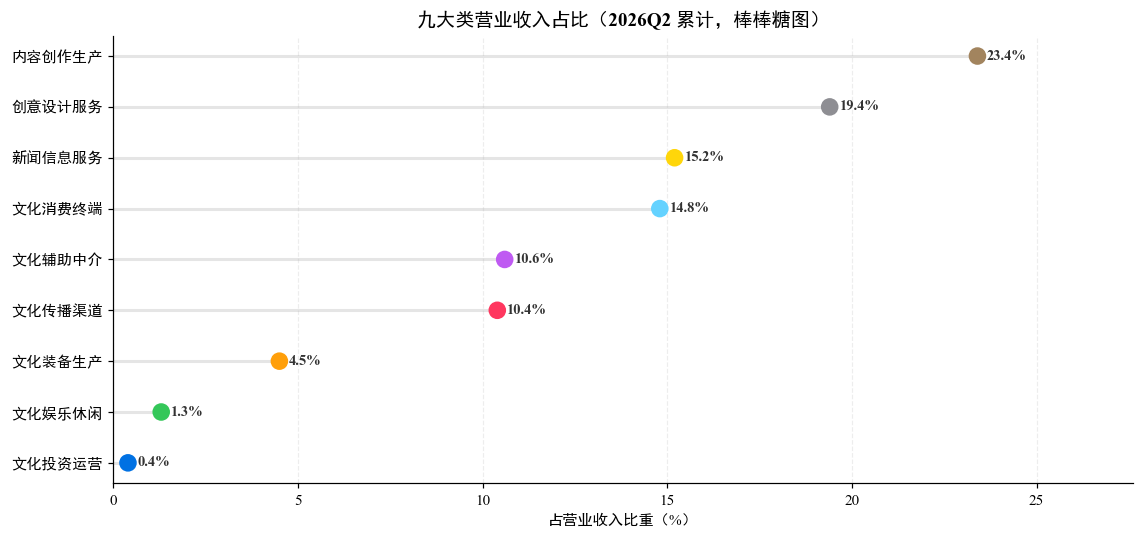

In [7]:
# 表 6：九大类营业收入比重（比重文件名与内容互换，按内容读取）
quarters, rows = load_table('按行业分规模以上文化及相关产业企业营业收入比重.csv')
latest = len(quarters) - 1

# 各大类比重指标的完整前缀（部分大类名称与简称不同）
IND_SHARE_PREFIX = {
    '新闻信息服务': '规模以上新闻信息服务营业收入所占比重累计值',
    '内容创作生产': '规模以上内容创作生产营业收入所占比重累计值',
    '创意设计服务': '规模以上创意设计服务营业收入所占比重累计值',
    '文化传播渠道': '规模以上文化传播渠道营业收入所占比重累计值',
    '文化投资运营': '规模以上文化投资运营营业收入所占比重累计值',
    '文化娱乐休闲': '规模以上文化娱乐休闲服务营业收入所占比重累计值',
    '文化辅助中介': '规模以上文化辅助生产和中介服务营业收入所占比重累计值',
    '文化装备生产': '规模以上文化装备生产营业收入所占比重累计值',
    '文化消费终端': '规模以上文化消费终端生产营业收入所占比重累计值',
}
pairs = sorted([(name, col(rows, IND_SHARE_PREFIX[name])[latest])
                for name, _ in INDUSTRIES], key=lambda t: t[1])
names = [p[0] for p in pairs]
shares = [p[1] for p in pairs]

fig, ax = plt.subplots(figsize=(10.5, 5.0))
ax.hlines(names, 0, shares, color=HAIR if (HAIR := '#e5e5e5') else HAIR, lw=2, zorder=1)
ax.scatter(shares, names, s=110, color=PAL[:len(names)], zorder=3)
for n, s in zip(names, shares):
    ax.text(s + 0.25, n, f'{s:.1f}%', va='center', fontsize=9.5,
            fontweight='bold', color='#333333')
ax.set_xlim(0, max(shares) * 1.18)
ax.set_xlabel('占营业收入比重（%）')
ax.set_title(f'九大类营业收入占比（{quarters[latest]} 累计，棒棒糖图）')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()